# 01 — Premier contact avec les données

Un tour d'horizon du train et du test : ce que contient chaque fichier, à quoi ressemble un spectre, d'où viennent les données, et combien de spectres on a par molécule. Pas encore de modèle ici.

Pour économiser la mémoire, on charge les **métadonnées** du train sans les tableaux de pics (0,75 Go au lieu de ~7 Go), et seulement quelques spectres quand on veut en regarder un.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import casmi

train = casmi.load_train_meta(casmi.META_COLUMNS + ["inchikey", "adduct_orig", "collision_energy_orig",
                                                    "collision_energy_orig_units"])
test = pd.read_parquet(casmi.paths.test)

## 1. Dimensions et colonnes

In [2]:
print("train :", train.shape, "(sans les 2 colonnes de pics)")
print("test  :", test.shape)
print()
print("colonnes du test absentes du train :", sorted(set(test.columns) - set(train.columns) - {"ms2_mzs", "ms2_normalized_intensities"}))
print("colonnes du train absentes du test :", sorted(set(train.columns) - set(test.columns)))

train : (2539608, 16) (sans les 2 colonnes de pics)
test  : (1213, 12)

colonnes du test absentes du train : ['molecule_id', 'spectrum_id']
colonnes du train absentes du test : ['adduct_orig', 'inchikey', 'inchikey14', 'ingest_lib', 'molecular_formula', 'normalized_smiles', 'num_peaks', 'precursor_error_ppm']


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2539608 entries, 0 to 2539607
Data columns (total 16 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   ingest_lib                   str    
 1   normalized_smiles            str    
 2   inchikey14                   str    
 3   molecular_formula            str    
 4   ionization_mode              str    
 5   instrument_type              str    
 6   adduct                       str    
 7   precursor_mz                 float64
 8   precursor_error_ppm          float64
 9   num_peaks                    int64  
 10  base_peak_intensity          float64
 11  collision_energy_ev          object 
 12  inchikey                     str    
 13  adduct_orig                  str    
 14  collision_energy_orig        str    
 15  collision_energy_orig_units  str    
dtypes: float64(3), int64(1), object(1), str(11)
memory usage: 649.6+ MB


Le train donne la réponse (`normalized_smiles`, et ses identifiants `inchikey` / `inchikey14`) et des informations de provenance (`ingest_lib`, `adduct_orig`…). Le test donne des identifiants anonymes : `molecule_id` regroupe les spectres d'une même molécule, et c'est **par molécule** qu'on doit répondre.

## 2. À quoi ressemble un spectre

Un spectre est une liste de pics : pour chaque fragment, sa masse sur charge (m/z) et son intensité (le pic le plus haut vaut 1).

**Attention au fichier `test.parquet` visible** : la page Données précise qu'il est *composé d'exemples du train* et qu'il sera remplacé par le vrai test caché au moment de la soumission. Le forum a vérifié qu'il s'agit de copies de spectres de `enveda-180` (chimie de synthèse). Il sert à montrer le format, pas à tirer des statistiques sur le vrai test.

In [4]:
i = 0
row = train.loc[i]
print("=== SPECTRE DU TRAIN ===")
for col in ["ingest_lib", "normalized_smiles", "inchikey", "molecular_formula", "ionization_mode",
            "instrument_type", "adduct", "precursor_mz", "collision_energy_ev", "num_peaks"]:
    print(f"{col:22s}: {row[col]}")

row_t = test.loc[i]
print("\n=== SPECTRE DU TEST ===")
for col in ["molecule_id", "spectrum_id", "ionization_mode", "instrument_type", "adduct",
            "precursor_mz", "collision_energy_ev"]:
    print(f"{col:22s}: {row_t[col]}")
print(f"{'nombre de pics':22s}: {len(row_t['ms2_mzs'])}")

=== SPECTRE DU TRAIN ===
ingest_lib            : drug_plus
normalized_smiles     : O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21
inchikey              : AAALVYBICLMAMA-UHFFFAOYSA-N
molecular_formula     : C20H15N3O2
ionization_mode       : positive
instrument_type       : nan
adduct                : [M+H]+
precursor_mz          : 330.1237
collision_energy_ev   : None
num_peaks             : 52

=== SPECTRE DU TEST ===
molecule_id           : m_005e53
spectrum_id           : s_4d19d522
ionization_mode       : positive
instrument_type       : timsTOF
adduct                : [M+H]+
precursor_mz          : 375.0709
collision_energy_ev   : [20. 40. 60.]
nombre de pics        : 183


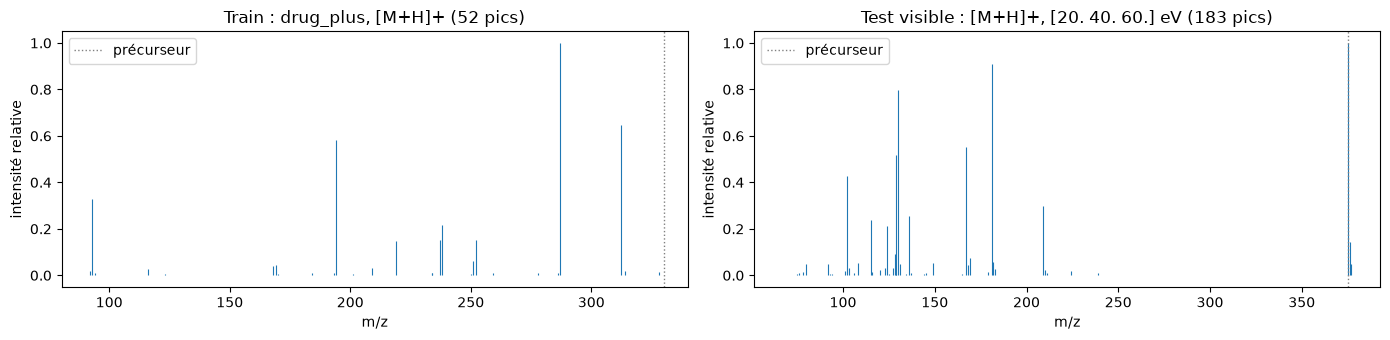

In [5]:
spec_train = casmi.load_train_spectra(np.array([i])).iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (mzs, ints), prec, title in [
    (axes[0], (spec_train["ms2_mzs"], spec_train["ms2_normalized_intensities"]), row["precursor_mz"],
     f"Train : {row['ingest_lib']}, {row['adduct']}"),
    (axes[1], (row_t["ms2_mzs"], row_t["ms2_normalized_intensities"]), row_t["precursor_mz"],
     f"Test visible : {row_t['adduct']}, {row_t['collision_energy_ev']} eV"),
]:
    ax.vlines(mzs, 0, ints, lw=0.8)
    ax.axvline(prec, color="grey", ls=":", lw=1, label="précurseur")
    ax.set(title=f"{title} ({len(mzs)} pics)", xlabel="m/z", ylabel="intensité relative")
    ax.legend()
plt.tight_layout()
plt.show()

## 3. D'où viennent les données

Le train agrège onze bibliothèques publiques, chacune avec ses instruments et ses conventions. L'instrument est du texte libre, avec de nombreuses écritures pour un même type de machine.

In [6]:
print("=== BIBLIOTHÈQUES ===")
print(train["ingest_lib"].value_counts(), "\n")
print("=== POLARITÉ ===")
print(train["ionization_mode"].value_counts(), "\n")
print(f"=== INSTRUMENTS ({train['instrument_type'].nunique()} écritures distinctes, 15 premières) ===")
print(train["instrument_type"].value_counts().head(15), "\n")
print(f"=== ADDUITS ({train['adduct'].nunique()} distincts, 15 premiers) ===")
print(train["adduct"].value_counts().head(15))

=== BIBLIOTHÈQUES ===
ingest_lib
enveda-180            1153785
pluskal_ms2            527581
riken                  347171
gnps                   220849
massbank               101727
mona                    92416
spectraverse            50933
msdial                  40765
drug_plus                2545
enveda-np-examples       1184
masaryk                   652
Name: count, dtype: int64 

=== POLARITÉ ===


ionization_mode
positive    1899640
negative     639968
Name: count, dtype: int64 

=== INSTRUMENTS (82 écritures distinctes, 15 premières) ===


instrument_type
timsTOF                  1154969
Orbitrap                  745562
QTOF                      125936
LC-ESI-QTOF               104482
ESI-QFT                    77342
LC-ESI-QFT                 55024
LC-ESI-ITFT                45109
qTof                       33777
ToF                        26535
qtof                       26111
LC-ESI-QQ                  19283
orbitrap                   15361
Linear Ion Trap            10241
Hybrid FT                   9137
Flow-injection QqQ/MS       8721
Name: count, dtype: int64 

=== ADDUITS (121 distincts, 15 premiers) ===


adduct
[M+H]+           1324585
[M-H]-            465688
[2M+Na]+          190033
[M+Na]+           178092
[2M+H]+            92041
[M+CH2O2-H]-       83188
[2M-H]-            56172
[M+NH4]+           53452
[M+Cl]-            27511
[M-H2O+H]+         21682
[M+K]+             18955
[M]+                8818
[M+C2H4O2-H]-       7436
[M-2H2O+H]+         3439
[M+2H]2+            1717
Name: count, dtype: int64


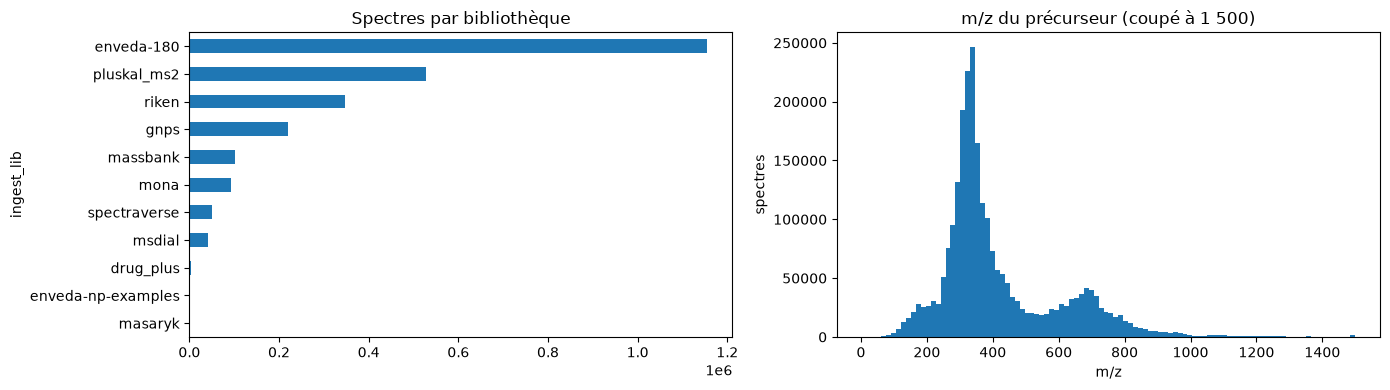

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train["ingest_lib"].value_counts().plot.barh(ax=axes[0], title="Spectres par bibliothèque")
axes[0].invert_yaxis()
axes[1].hist(train["precursor_mz"].clip(upper=1500), bins=100)
axes[1].set(title="m/z du précurseur (coupé à 1 500)", xlabel="m/z", ylabel="spectres")
plt.tight_layout()
plt.show()

## 4. Combien de spectres par molécule ?

Une même molécule (même connectivité, `inchikey14`) apparaît souvent plusieurs fois : à plusieurs énergies de collision, avec plusieurs adduits, dans plusieurs bibliothèques.

In [8]:
spectra_per_molecule = train.groupby("inchikey14").size()

print("=== DISTRIBUTION DU NOMBRE DE SPECTRES PAR CONNECTIVITÉ ===")
print(spectra_per_molecule.describe(percentiles=[.50, .75, .90, .95, .99, .999]))

print("\n=== QUELQUES SEUILS ===")
for n in [1, 2, 5, 10, 20, 50, 100, 500, 1000]:
    print(f">= {n:4d} spectres :", (spectra_per_molecule >= n).sum())

=== DISTRIBUTION DU NOMBRE DE SPECTRES PAR CONNECTIVITÉ ===
count    275810.000000
mean          9.207817
std          21.069560
min           1.000000
50%           6.000000
75%           9.000000
90%          14.000000
95%          21.000000
99%          79.000000
99.9%       286.000000
max        1468.000000
dtype: float64

=== QUELQUES SEUILS ===
>=    1 spectres : 275810
>=    2 spectres : 258777
>=    5 spectres : 165492
>=   10 spectres : 63821
>=   20 spectres : 15427
>=   50 spectres : 5509
>=  100 spectres : 1879
>=  500 spectres : 71
>= 1000 spectres : 5


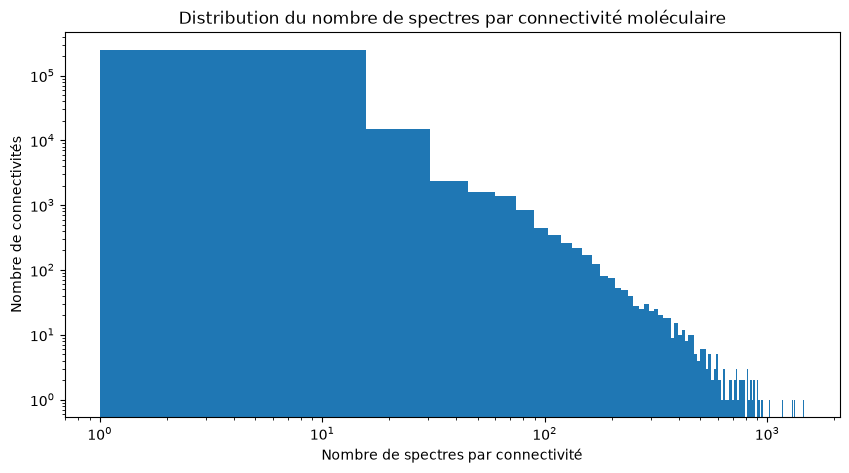

Connectivités avec un seul spectre : 17,033 sur 275,810 (6.2 %)


In [9]:
plt.figure(figsize=(10, 5))
plt.hist(spectra_per_molecule, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Nombre de spectres par connectivité")
plt.ylabel("Nombre de connectivités")
plt.title("Distribution du nombre de spectres par connectivité moléculaire")
plt.show()

print(f"Connectivités avec un seul spectre : {(spectra_per_molecule == 1).sum():,} "
      f"sur {len(spectra_per_molecule):,} ({100 * (spectra_per_molecule == 1).mean():.1f} %)")

In [10]:
# La connectivité la plus représentée : d'où viennent ses spectres ?
ik = spectra_per_molecule.idxmax()
same = train[train["inchikey14"] == ik]

print("InChIKey14 :", ik, "|", same["normalized_smiles"].iloc[0])
print("Nombre de spectres :", len(same))
print("InChIKeys complets :", same["inchikey"].nunique(), "(variantes de stéréochimie)")
print("Bibliothèques :", same["ingest_lib"].nunique(), "| instruments :", same["instrument_type"].nunique(),
      "| adduits :", same["adduct"].nunique())
print("\n--- bibliothèques ---")
print(same["ingest_lib"].value_counts())
print("\n--- adduits ---")
print(same["adduct"].value_counts().head(10))

InChIKey14 : PFTAWBLQPZVEMU | Oc1cc(O)c2c(c1)OC(c1ccc(O)c(O)c1)C(O)C2
Nombre de spectres : 1468
InChIKeys complets : 1 (variantes de stéréochimie)
Bibliothèques : 8 | instruments : 27 | adduits : 12

--- bibliothèques ---
ingest_lib
riken                 716
gnps                  373
massbank              147
mona                  116
msdial                 58
pluskal_ms2            53
enveda-np-examples      4
drug_plus               1
Name: count, dtype: int64

--- adduits ---
adduct
[M+H]+          724
[M-H]-          413
[M+Na]+         271
[2M-H]-          16
[M+CH2O2-H]-     14
[2M+NH4]+         8
[M-H2O+H]+        8
[M-H2]2-          5
[M+Cl]-           4
[M-H2O-H]-        3
Name: count, dtype: int64


## À retenir

- Le train contient 2,5 M spectres pour ~276 000 connectivités, issus de onze bibliothèques très hétérogènes (instruments, conventions, adduits).
- Le `test.parquet` visible n'est qu'un exemple de format : le vrai test (produits naturels mesurés sur timsTOF) reste caché.
- Une molécule a en général **plusieurs spectres**, souvent répartis entre plusieurs bibliothèques. Pour mesurer honnêtement la capacité à identifier une molécule **jamais vue**, il faudra donc cacher **tous** ses spectres à la fois, et pas un seul.

C'est l'objet du notebook **02 — validation**.